# Exploratory Data Analysis (EDA) — Dataset Berita STKI

Notebook ini mengeksplorasi `data/processed/indonesia_news_clean.csv` sebagai dasar **mesin pencari berita (TF-IDF + Cosine Similarity)**.
Berbeda dari EDA tabular biasa, di sini fokusnya pada hal-hal yang memengaruhi kualitas *information retrieval*:

| Bagian | Pertanyaan yang dijawab |
|---|---|
| 1–3 | Seperti apa bentuk data, apakah ada nilai kosong dan duplikasi? |
| 4–5 | Bagaimana sebaran sumber berita dan rentang waktunya? |
| 6–7 | Seberapa panjang dokumen dan judulnya? Ada outlier? |
| 8 | Bagaimana kualitas dan sebaran tag? |
| 9 | Noise apa yang ada di teks dan apakah `clean_text` sudah membersihkannya? |
| 10 | Bagaimana efek preprocessing terhadap ukuran kosakata? |
| 11–13 | Kata apa yang dominan, mana kandidat stopword domain, dan apakah korpus mengikuti hukum Zipf? |
| 14 | Frasa (bigram) apa yang sering muncul? |
| 15 | Kata apa yang khas tiap portal, seberapa *sparse* matriks TF-IDF, dan adakah dokumen yang hampir kembar? |
| 16 | Apakah korpus mampu menjawab contoh query pengujian? |
| 17 | Ringkasan temuan dan rekomendasi |

> **Catatan:** sel stemming memakai cache `data/index/stem_cache.json`. Tanpa cache itu, stemming Sastrawi untuk seluruh kosakata memakan waktu beberapa menit pada eksekusi pertama.

## 0. Setup

In [1]:
import sys, re, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings("ignore")

# Pastikan notebook bisa mengimpor paket `src` dari root proyek
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import DATASET_PATH
from src.preprocessing import clean_text, base_tokens, stem_tokens, remove_stopwords, preprocess, STOPWORDS

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

SOURCES = ["kompas", "tempo", "detik"]
COLORS = {"kompas": "#2563eb", "tempo": "#dc2626", "detik": "#16a34a"}
print("Dataset:", DATASET_PATH)

Dataset: /home/claude/stki-final-project/data/processed/indonesia_news_clean.csv


## 1. Gambaran Umum Data

In [2]:
df = pd.read_csv(DATASET_PATH)
print(f"Jumlah dokumen : {df.shape[0]}")
print(f"Jumlah kolom   : {df.shape[1]}")
print(f"Ukuran memori  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
df.info()

Jumlah dokumen : 500
Jumlah kolom   : 10
Ukuran memori  : 1.96 MB
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Judul    500 non-null    str  
 1   Waktu    500 non-null    str  
 2   Link     500 non-null    str  
 3   Content  500 non-null    str  
 4   tag1     485 non-null    str  
 5   tag2     483 non-null    str  
 6   tag3     456 non-null    str  
 7   tag4     352 non-null    str  
 8   tag5     209 non-null    str  
 9   source   500 non-null    str  
dtypes: str(10)
memory usage: 39.2 KB


In [3]:
pd.set_option("display.max_colwidth", 80)
df.head(5)

,Judul,Waktu,Link,Content,tag1,tag2,tag3,tag4,tag5,source
0,"Viral Isu PHK Buruh Gudang Garam, Said Iqbal: Suplier hingga Pemilik Kontrak...",6 September 2025,https://nasional.kompas.com/read/2025/09/06/14232881/viral-isu-phk-buruh-gud...,"JAKARTA, KOMPAS.com – Presiden Konfederasi Serikat Pekerja Indonesia (KSPI)...",Said Iqbal,industri rokok,PT Gudang Garam,PHK massal,phk massal 2025 terbaru,kompas
1,"Gempa M 5,3 Guncang Pulau Doi Maluku Utara","Senin, 12 Agu 2024 21:58 WIB",https://news.detik.com/berita/d-7486691/gempa-m-5-3-guncang-pulau-doi-maluku...,"Gempa bumi berkekuatan magnitudo (M) 5,3 mengguncang Kabupaten Pulau Doi, Ma...",pulau doi,gempa,NaN,NaN,NaN,detik
2,"Toko Emas Palsu di Riau Dibongkar Polisi, Perhiasan 1,8 Kg Disita","Rabu, 30 Jul 2025 22:22 WIB",https://news.detik.com/melindungi-tuah-marwah/d-8037655/toko-emas-palsu-di-r...,Satreskrim Polres Bengkalis membongkar praktik pemalsuan emas di sebuah toko...,pemalsuan emas,emas palsu,polres bengkalis,polda riau,melindungi tuah marwah,detik
3,"Minyakita Tak Sesuai Ukuran juga Ditemukan di Kudus, Disita Polda Jateng","Senin, 10 Mar 2025 23:15 WIB",https://news.detik.com/berita/d-7816829/minyakita-tak-sesuai-ukuran-juga-dit...,Polisi mendatangi salah satu gudang Minyakita yang disunat isi kemasannya di...,minyakita,kudus,NaN,NaN,NaN,detik
4,"Pimpin LDP, Sanae Takaichi Calon Kuat PM Perempuan Pertama Jepang",4 Oktober 2025 | 14.00 WIB,https://www.tempo.co/internasional/pimpin-ldp-sanae-takaichi-calon-kuat-pm-p...,"Baca berita dengan sedikit iklan, klik di sini Mantan Menteri Keamanan Eko...",jepang,perdana-menteri,sanae-takaichi,perempuan,ldp,tempo


Kolom penting untuk IR: **`Judul`** dan **`Content`** (teks yang diindeks), **`Link`** (identitas unik artikel), **`source`** (portal berita), serta **`tag1`–`tag5`** (kata kunci dari portal). `Waktu` berformat teks dan berbeda tiap portal, jadi perlu distandarkan (bagian 5).

## 2. Nilai Kosong (Missing Values)

,jumlah,persen
Judul,0,0.0
Waktu,0,0.0
Link,0,0.0
Content,0,0.0
tag1,15,3.0
tag2,17,3.4
tag3,44,8.8
tag4,148,29.6
tag5,291,58.2
source,0,0.0


Content kosong/hanya spasi : 0
Judul   kosong/hanya spasi : 0


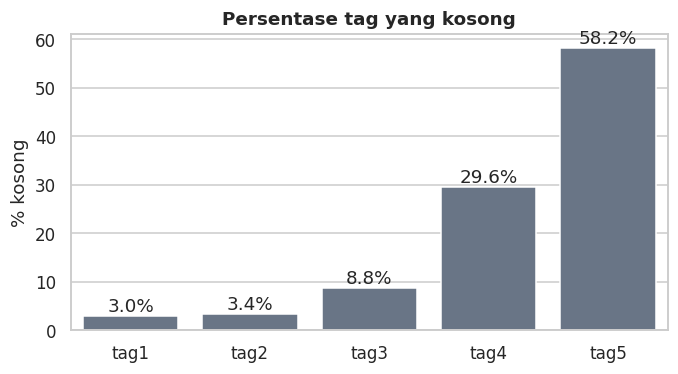

In [4]:
missing = df.isna().sum().to_frame("jumlah")
missing["persen"] = (missing["jumlah"] / len(df) * 100).round(1)
display(missing)

# Teks yang tampak terisi tetapi sebenarnya kosong/hanya spasi
print("Content kosong/hanya spasi :", (df["Content"].fillna("").str.strip() == "").sum())
print("Judul   kosong/hanya spasi :", (df["Judul"].fillna("").str.strip() == "").sum())

fig, ax = plt.subplots(figsize=(7, 3.5))
tag_missing = missing.loc[[f"tag{i}" for i in range(1, 6)], "persen"]
sns.barplot(x=tag_missing.index, y=tag_missing.values, color="#64748b", ax=ax)
for i, v in enumerate(tag_missing.values):
    ax.text(i, v + 0.8, f"{v}%", ha="center")
ax.set(title="Persentase tag yang kosong", ylabel="% kosong", xlabel="")
plt.show()

**Interpretasi:** kolom yang dipakai untuk pencarian (`Judul`, `Content`) lengkap. Nilai kosong hanya ada di kolom tag, dan itu wajar karena tidak semua artikel memiliki lima tag. Karena itu tag **tidak perlu dibuang** dan tidak perlu diimputasi; cukup diperlakukan sebagai metadata opsional.

## 3. Duplikasi

In [5]:
dup = pd.Series({
    "Link duplikat": df["Link"].duplicated().sum(),
    "Judul duplikat": df["Judul"].duplicated().sum(),
    "Content duplikat": df["Content"].duplicated().sum(),
    "Awal Content (200 huruf) duplikat": df["Content"].str[:200].duplicated().sum(),
    "Baris duplikat penuh": df.duplicated().sum(),
}, name="jumlah")
display(dup.to_frame())

,jumlah
Link duplikat,0
Judul duplikat,0
Content duplikat,0
Awal Content (200 huruf) duplikat,0
Baris duplikat penuh,0


Dokumen duplikat akan memenuhi daftar hasil dengan artikel yang sama dan menggeser artikel lain dari peringkat atas. Kalau angka di atas 0, hapus duplikat sebelum membuat indeks. Pengecekan **kemiripan hampir-kembar** (bukan hanya persis sama) ada di bagian 15.

## 4. Distribusi Sumber Berita

,jumlah,persen
source,,
kompas,236,47.2
tempo,139,27.8
detik,125,25.0


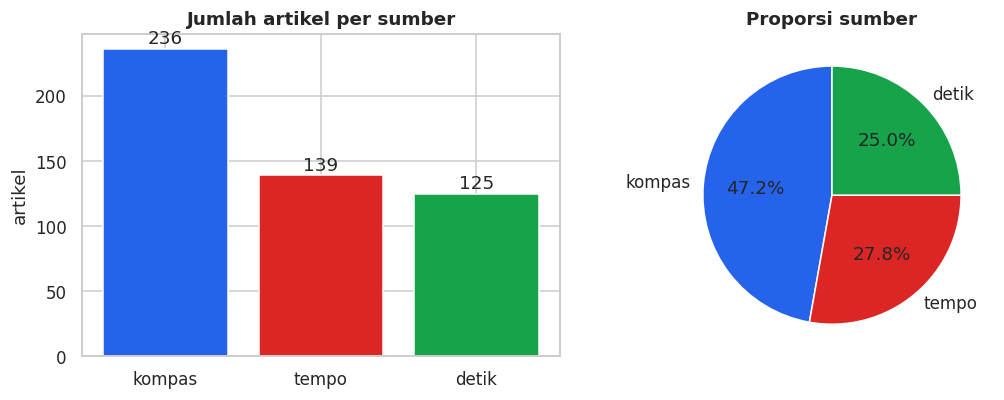

In [6]:
src_count = df["source"].value_counts().reindex(SOURCES)
src_pct = (src_count / len(df) * 100).round(1)
display(pd.DataFrame({"jumlah": src_count, "persen": src_pct}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(src_count.index, src_count.values, color=[COLORS[s] for s in src_count.index])
for i, v in enumerate(src_count.values):
    axes[0].text(i, v + 4, str(v), ha="center")
axes[0].set(title="Jumlah artikel per sumber", ylabel="artikel")
axes[1].pie(src_count.values, labels=src_count.index, autopct="%1.1f%%",
            colors=[COLORS[s] for s in src_count.index], startangle=90)
axes[1].set_title("Proporsi sumber")
plt.tight_layout(); plt.show()

Sebaran sumber tidak seimbang. Ini penting saat evaluasi: hasil pencarian cenderung didominasi portal yang paling banyak artikelnya, dan gaya bahasa tiap portal berbeda (lihat bagian 9 dan 15).

## 5. Analisis Waktu Terbit

Format `Waktu` berbeda di tiap portal (misalnya `6 September 2025`, `Senin, 12 Agu 2024 21:58 WIB`, `4 Oktober 2025 | 14.00 WIB`). Kita ubah semuanya menjadi `datetime`.

In [7]:
BULAN = {
    "januari": 1, "jan": 1, "februari": 2, "feb": 2, "maret": 3, "mar": 3,
    "april": 4, "apr": 4, "mei": 5, "juni": 6, "jun": 6, "juli": 7, "jul": 7,
    "agustus": 8, "agu": 8, "september": 9, "sep": 9, "oktober": 10, "okt": 10,
    "november": 11, "nov": 11, "desember": 12, "des": 12,
}

def parse_waktu(teks):
    m = re.search(r"(\d{1,2})\s+([A-Za-z]+)\s+(\d{4})", str(teks))
    if not m:
        return pd.NaT, False
    hari, nama_bulan, tahun = m.groups()
    bulan = BULAN.get(nama_bulan.lower())
    if bulan is None:
        return pd.NaT, False
    jam = re.search(r"(\d{1,2})[.:](\d{2})", str(teks)[m.end():])
    h, mnt = (int(jam.group(1)), int(jam.group(2))) if jam else (0, 0)
    return pd.Timestamp(int(tahun), bulan, int(hari), h, mnt), bool(jam)

parsed = df["Waktu"].map(parse_waktu)
df["waktu_dt"] = parsed.map(lambda x: x[0])
df["ada_jam"] = parsed.map(lambda x: x[1])

print("Gagal diparse :", df["waktu_dt"].isna().sum())
print("Rentang tanggal:", df["waktu_dt"].min().date(), "s.d.", df["waktu_dt"].max().date())
print("Artikel yang memiliki jam terbit per sumber:")
display(df.groupby("source")["ada_jam"].mean().mul(100).round(0).reindex(SOURCES).to_frame("% punya jam"))

Gagal diparse : 0
Rentang tanggal: 2024-07-31 s.d. 2025-10-23
Artikel yang memiliki jam terbit per sumber:


,% punya jam
source,
kompas,0.0
tempo,100.0
detik,100.0


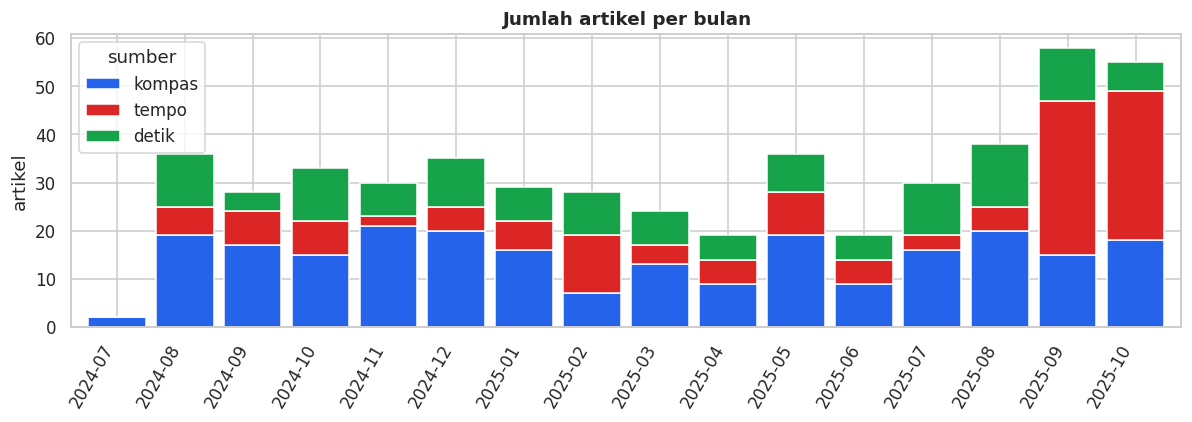

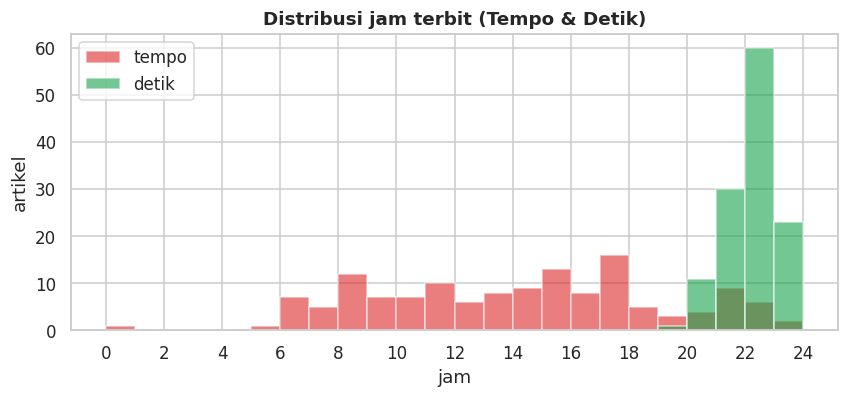

In [8]:
df["bulan"] = df["waktu_dt"].dt.to_period("M")
per_bulan = pd.crosstab(df["bulan"], df["source"]).reindex(columns=SOURCES, fill_value=0)

ax = per_bulan.plot(kind="bar", stacked=True, figsize=(11, 4),
                    color=[COLORS[s] for s in per_bulan.columns], width=0.85)
ax.set(title="Jumlah artikel per bulan", xlabel="", ylabel="artikel")
plt.xticks(rotation=60, ha="right"); plt.legend(title="sumber"); plt.tight_layout(); plt.show()

# Jam terbit (hanya sumber yang menyertakan jam)
jam_df = df[df["ada_jam"]]
fig, ax = plt.subplots(figsize=(9, 3.5))
for s in ["tempo", "detik"]:
    sub = jam_df[jam_df["source"] == s]["waktu_dt"].dt.hour
    ax.hist(sub, bins=range(0, 25), alpha=0.6, label=s, color=COLORS[s])
ax.set(title="Distribusi jam terbit (Tempo & Detik)", xlabel="jam", ylabel="artikel", xticks=range(0, 25, 2))
ax.legend(); plt.show()

**Interpretasi:** setelah diseragamkan, `waktu_dt` bisa dipakai untuk filter tanggal atau pengurutan hasil (misalnya "terbaru"). Kompas tidak menyertakan jam, jadi analisis jam hanya valid untuk Tempo dan Detik.

> **Anomali:** hampir semua artikel Detik (sekitar 99%) bertanda jam antara 19.00 dan 23.59 WIB, sedangkan Tempo tersebar sepanjang hari. Berita sungguhan tidak mungkin terbit hanya pada jam-jam itu, jadi jam Detik kemungkinan besar bukan jam terbit asli (misalnya berasal dari waktu scraping, zona waktu yang tergeser, atau elemen halaman yang salah terambil). **Jangan memakai jam Detik sebagai fitur**; tanggalnya masih bisa dipakai, tetapi sebaiknya diverifikasi ke sumber sebelum dijadikan dasar analisis tren harian. Perhatikan juga apakah sebaran bulan merata, karena sebaran waktu yang sangat miring bisa membuat query bertopik musiman hanya menemukan sedikit dokumen.

## 6. Panjang Dokumen

In [9]:
df["isi_bersih"] = df["Content"].fillna("").map(clean_text)
df["n_char"] = df["Content"].fillna("").str.len()
df["n_kata"] = df["isi_bersih"].str.split().str.len()

display(df["n_kata"].describe().round(1).to_frame("jumlah kata"))
display(df.groupby("source")["n_kata"].describe().round(1).reindex(SOURCES))

,jumlah kata
count,500.0
mean,311.9
std,141.8
min,48.0
25%,236.0
50%,295.0
75%,356.0
max,1695.0


,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
kompas,236.0,278.9,79.7,69.0,232.0,277.0,327.2,746.0
tempo,139.0,352.9,165.6,48.0,263.0,335.0,440.0,941.0
detik,125.0,328.5,184.9,85.0,230.0,295.0,380.0,1695.0


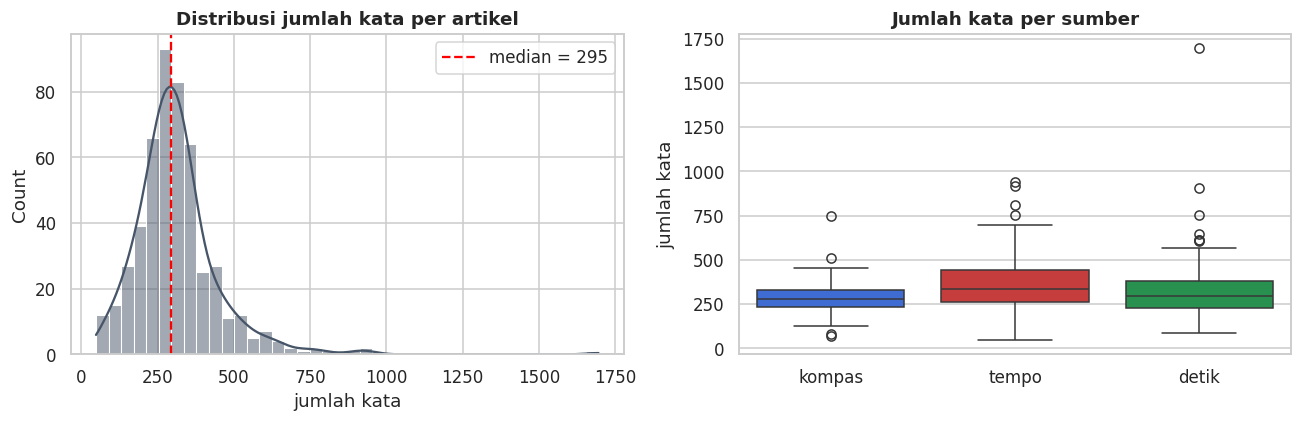

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["n_kata"], bins=40, kde=True, color="#475569", ax=axes[0])
axes[0].axvline(df["n_kata"].median(), color="red", ls="--", label=f"median = {df['n_kata'].median():.0f}")
axes[0].set(title="Distribusi jumlah kata per artikel", xlabel="jumlah kata"); axes[0].legend()

sns.boxplot(data=df, x="source", y="n_kata", order=SOURCES, palette=COLORS, ax=axes[1])
axes[1].set(title="Jumlah kata per sumber", xlabel="", ylabel="jumlah kata")
plt.tight_layout(); plt.show()

In [11]:
# Deteksi outlier dengan aturan IQR
q1, q3 = df["n_kata"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
batas_bawah = max(0, q1 - 1.5 * (q3 - q1))
outlier = df[(df["n_kata"] > batas_atas) | (df["n_kata"] < batas_bawah)]
print(f"Batas wajar: {batas_bawah:.0f} - {batas_atas:.0f} kata  |  outlier: {len(outlier)} artikel ({len(outlier)/len(df):.1%})")
display(outlier.sort_values("n_kata", ascending=False)[["Judul", "source", "n_kata"]].head(8))

Batas wajar: 56 - 536 kata  |  outlier: 28 artikel (5.6%)


,Judul,source,n_kata
485,Daftar Lengkap Identitas 63 Jenazah Korban Tewas Ponpes Al Khoziny Ambruk,detik,1695
134,Donald Trump Tawarkan Kartu Emas: Miliarder Rusia Boleh Ajukan Permohonan,tempo,941
137,IKRA Sukses Mengantarkan Desainer Berdaya di ISEF 2025,tempo,918
261,5 Hal Diketahui dari Putusan MK soal UU Cipta Kerja,detik,907
72,Pemerintah Gandeng Akademisi Jalani Pemantauan Aktif Vaksinasi DBD pada Anak,tempo,807
34,Anggota DPRD DKI Kenneth Usulkan Calon Petugas PPSU Wajib Ber-KTP Jakarta,detik,756
218,"Rekam Jejak Johanis Tanak, Petahana Kontroversial yang Lolos Tes Tulis Capim...",tempo,752
431,"Surabaya Gelontorkan Rp 42,7 Miliar, Bonus untuk Atlet Porprov Jatim 2025",kompas,746


**Mengapa ini penting untuk IR:** TF-IDF dengan normalisasi L2 sudah meredam efek panjang dokumen, tetapi artikel yang sangat panjang tetap memuat banyak topik sehingga lebih mudah muncul untuk banyak query. Artikel yang sangat pendek bisa terlalu sedikit informasinya untuk dicocokkan. Outlier di atas layak dicek manual, apakah ia artikel sah atau hasil scraping yang berantakan.

## 7. Panjang Judul

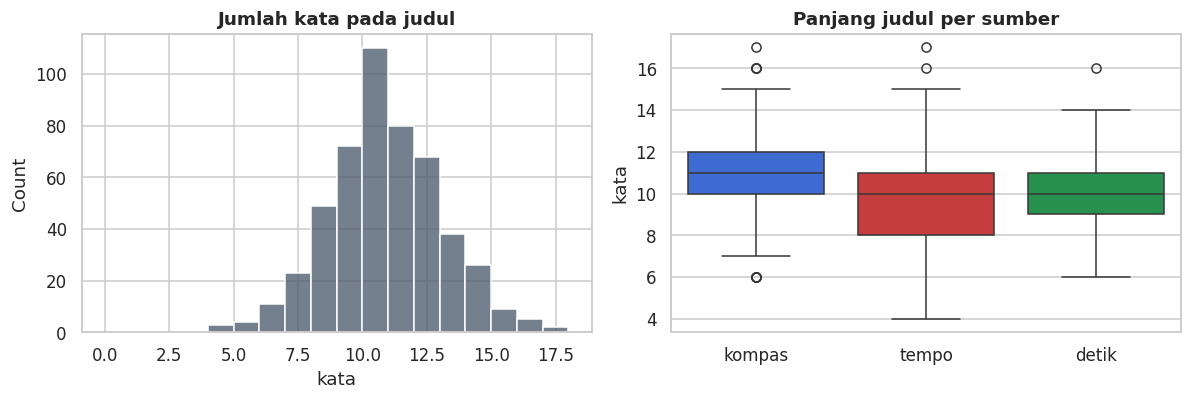

count    500.0
mean      10.4
std        2.2
min        4.0
25%        9.0
50%       10.0
75%       12.0
max       17.0


In [12]:
df["n_kata_judul"] = df["Judul"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["n_kata_judul"], bins=range(0, df["n_kata_judul"].max() + 2), color="#475569", ax=axes[0])
axes[0].set(title="Jumlah kata pada judul", xlabel="kata")
sns.boxplot(data=df, x="source", y="n_kata_judul", order=SOURCES, palette=COLORS, ax=axes[1])
axes[1].set(title="Panjang judul per sumber", xlabel="", ylabel="kata")
plt.tight_layout(); plt.show()
print(df["n_kata_judul"].describe().round(1).to_string())

Judul pendek tetapi padat informasi. Karena itu pada `SearchEngine.build` judul diulang dua kali sebelum diproses, agar kata di judul punya bobot lebih besar daripada kata di isi.

## 8. Analisis Tag

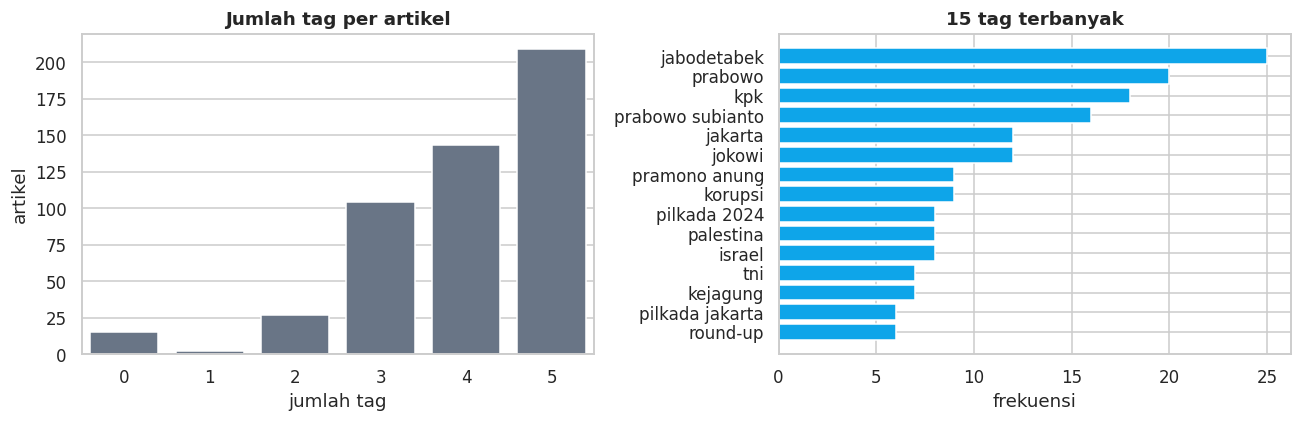

Total tag: 1985  |  tag unik: 1571  |  artikel tanpa tag: 15


In [13]:
tag_cols = [f"tag{i}" for i in range(1, 6)]
df["n_tag"] = df[tag_cols].notna().sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="n_tag", data=df, color="#64748b", ax=axes[0])
axes[0].set(title="Jumlah tag per artikel", xlabel="jumlah tag", ylabel="artikel")

all_tags = pd.Series([str(t).strip().lower() for t in df[tag_cols].values.ravel() if pd.notna(t)])
top_tags = all_tags.value_counts().head(15)
axes[1].barh(top_tags.index[::-1], top_tags.values[::-1], color="#0ea5e9")
axes[1].set(title="15 tag terbanyak", xlabel="frekuensi")
plt.tight_layout(); plt.show()

print(f"Total tag: {len(all_tags)}  |  tag unik: {all_tags.nunique()}  |  artikel tanpa tag: {(df['n_tag'] == 0).sum()}")

In [14]:
# 5 tag teratas di tiap sumber
rows = {}
for s in SOURCES:
    t = pd.Series([str(x).strip().lower() for x in df.loc[df["source"] == s, tag_cols].values.ravel() if pd.notna(x)])
    rows[s] = t.value_counts().head(5).index.tolist() + [""] * max(0, 5 - t.nunique())
display(pd.DataFrame(rows, index=[f"#{i}" for i in range(1, 6)]))

,kompas,tempo,detik
#1,prabowo subianto,prabowo,jabodetabek
#2,pramono anung,kpk,prabowo subianto
#3,jakarta,palestina,kpk
#4,jokowi,jokowi,jakarta
#5,pilkada jakarta,prabowo-subianto,round-up


Tag adalah metadata yang dibuat redaksi, sehingga berpotensi menjadi **fitur tambahan** (misalnya filter atau boost skor) atau dijadikan *ground truth* topik saat evaluasi relevansi. Tag yang sangat umum bisa dipakai sebagai kategori, sedangkan tag yang muncul sekali saja terlalu spesifik untuk pengelompokan.

## 9. Deteksi Noise pada Teks

Teks hasil scraping biasanya membawa sisa elemen halaman. Noise ini ikut terhitung sebagai kata dan merusak bobot TF-IDF. Berikut sebaran noise per sumber dan hasil `clean_text` setelah membersihkannya.

In [15]:
NOISE = {
    'Tempo: "Baca berita dengan sedikit iklan"': r"baca berita dengan sedikit iklan",
    'Tempo: "Scroll ke bawah untuk melanjutkan membaca"': r"scroll ke bawah untuk melanjutkan membaca",
    'Tempo: "Pilihan Editor: <judul berita lain>"': r"pilihan editor\s*:",
    'Kompas: dateline "KOTA, KOMPAS.com -"': r"^\s*[A-Z][A-Za-z ,.\-]{2,40},\s*KOMPAS\.com",
    'Detik: "Simak (juga) video"': r"simak\s*(?:juga)?\s*:?\s*video\b",
    "Detik: tag [Gambas:...]": r"\[gambas",
    'Detik: "Simak ... di halaman selanjutnya"': r"simak [^.:]{0,60}halaman selanjutnya",
    'Detik: "Baca selengkapnya di sini"': r"baca selengkapnya di sini",
    '"Baca juga:"': r"baca juga",
    "URL (http / www)": r"https?://|www\.",
    "Spasi non-breaking (NBSP)": "\xa0",
}
mentah = df["Content"].fillna("")
rows = []
for nama, pola in NOISE.items():
    ada_mentah = mentah.str.contains(pola, case=False, regex=True)
    ada_bersih = df["isi_bersih"].str.contains(pola, case=False, regex=True)
    per_src = ada_mentah.groupby(df["source"]).sum().reindex(SOURCES)
    rows.append({"pola": nama, **per_src.to_dict(), "total sebelum": int(ada_mentah.sum()), "sisa setelah clean_text": int(ada_bersih.sum())})
noise_df = pd.DataFrame(rows).set_index("pola")
display(noise_df)

,kompas,tempo,detik,total sebelum,sisa setelah clean_text
pola,,,,,
"Tempo: ""Baca berita dengan sedikit iklan""",0,133,0,133,0
"Tempo: ""Scroll ke bawah untuk melanjutkan membaca""",0,123,0,123,0
"Tempo: ""Pilihan Editor: <judul berita lain>""",0,101,0,101,0
"Kompas: dateline ""KOTA, KOMPAS.com -""",226,0,0,226,0
"Detik: ""Simak (juga) video""",0,0,26,26,0
Detik: tag [Gambas:...],0,0,55,55,0
"Detik: ""Simak ... di halaman selanjutnya""",0,0,6,6,0
"Detik: ""Baca selengkapnya di sini""",0,1,5,6,0
"""Baca juga:""",0,0,0,0,0


In [16]:
# Contoh sebelum / sesudah pembersihan, satu artikel per sumber
for s in SOURCES:
    r = df[df["source"] == s].iloc[0]
    print(f"[{s.upper()}] {r['Judul'][:90]}")
    print("  SEBELUM :", repr(r["Content"][:170]))
    print("  SESUDAH :", repr(r["isi_bersih"][:170]), "\n")

[KOMPAS] Viral Isu PHK Buruh Gudang Garam, Said Iqbal: Suplier hingga Pemilik Kontrakan Juga Akan T
  SEBELUM : ' JAKARTA, KOMPAS.com –\xa0Presiden Konfederasi Serikat Pekerja Indonesia (KSPI) Said Iqbal mengatakan, kabar pemutusan hubungan kerja (PHK) buruh pabrik rokok PT Gudang Gara'
  SESUDAH : 'Presiden Konfederasi Serikat Pekerja Indonesia (KSPI) Said Iqbal mengatakan, kabar pemutusan hubungan kerja (PHK) buruh pabrik rokok PT Gudang Garam bisa berdampak luas. ' 

[TEMPO] Pimpin LDP, Sanae Takaichi Calon Kuat PM Perempuan Pertama Jepang
  SEBELUM : 'Baca berita dengan sedikit iklan,  klik di sini  Mantan Menteri Keamanan Ekonom, Sanae Takaichi pada Sabtu 4 Oktober 2025 terpilih sebagai ketua perempuan pertama Partai '
  SESUDAH : 'Mantan Menteri Keamanan Ekonom, Sanae Takaichi pada Sabtu 4 Oktober 2025 terpilih sebagai ketua perempuan pertama Partai Demokrat Liberal (LDP) — dan hampir pasti akan me' 

[DETIK] Gempa M 5,3 Guncang Pulau Doi Maluku Utara
  SEBELUM : 'Gempa bumi berk

Kolom **"sisa setelah clean_text"** adalah ukuran keberhasilan pembersihan. Nilai yang masih di atas 0 berarti ada pola yang belum tertangani dan perlu ditambahkan ke `_NOISE_PATTERNS` di `src/preprocessing.py`. Setelah pembersihan, semua pola yang dipantau di atas sudah tidak tersisa. Pengecualiannya adalah spasi non-breaking, yang memang tidak ditangani di sini karena bukan kata dan tidak memengaruhi tokenisasi. Variasi penulisan yang sangat jarang (misalnya kredit "Editor: ... Videographer" di akhir artikel Tempo) sengaja tidak dibersihkan dengan regex. Sebutan "Kompas.com" di tengah kalimat (misalnya *"kata dia kepada Kompas.com"*) memang tidak dihapus karena itu bagian dari kalimat, dan kata `kompas` sudah masuk daftar stopword.

> **Catatan proses:** noise Tempo (*Scroll ke bawah...*, *Pilihan Editor...*) dan Detik (*halaman selanjutnya*, *Baca selengkapnya*) awalnya lolos dari pembersihan dan baru ketahuan lewat analisis ini: kata `scroll`, `editor`, dan `lanjut` muncul sebagai kata "khas" Tempo di bagian 15. Pola-pola tersebut kini sudah ditangani di `clean_text`.

## 10. Efek Preprocessing terhadap Kosakata

Tiap tahap pipeline menyusutkan jumlah token dan ukuran kosakata. Ukuran kosakata menentukan dimensi vektor TF-IDF.

,total token,kosakata unik,rata-rata token/dokumen
tahap,,,
1. Cleaning + tokenizing,152393,14090,304.8
2. + Stopword removal,109515,13947,219.0
3. + Stemming,103303,9744,206.6


Penyusutan kosakata dari tahap 1 ke 3: 30.8%


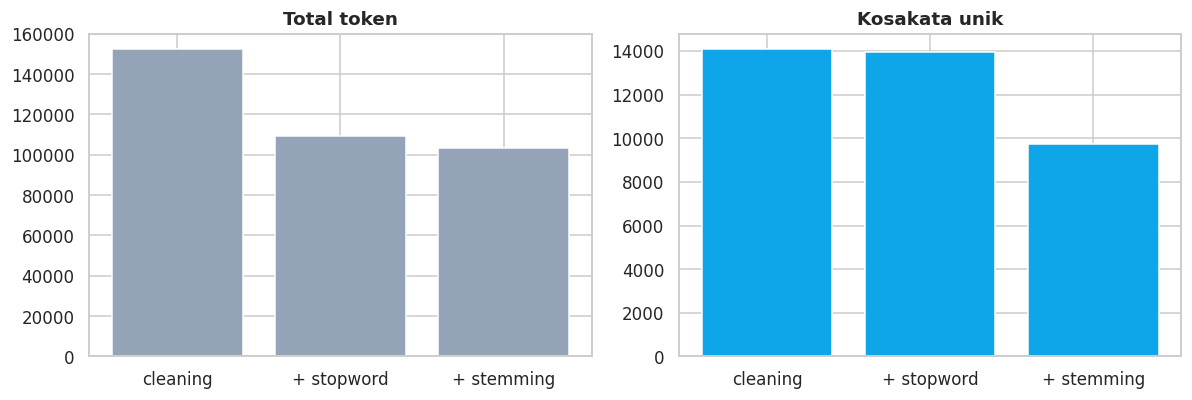

In [17]:
# Tahap 1: cleaning + case folding + tokenizing (tanpa stopword removal)
df["tok_mentah"] = df["isi_bersih"].str.lower().str.findall(r"[a-z]{2,}")
# Tahap 2: stopword removal
df["tok_nostop"] = df["Content"].fillna("").map(base_tokens)
# Tahap 3: stemming Sastrawi (memakai cache stemming)
df["tok_stem"] = df["tok_nostop"].map(lambda t: remove_stopwords(stem_tokens(t)))

tahap = {
    "1. Cleaning + tokenizing": "tok_mentah",
    "2. + Stopword removal": "tok_nostop",
    "3. + Stemming": "tok_stem",
}
stat = []
for nama, kol in tahap.items():
    semua = [w for t in df[kol] for w in t]
    stat.append({"tahap": nama, "total token": len(semua), "kosakata unik": len(set(semua)),
                 "rata-rata token/dokumen": round(len(semua) / len(df), 1)})
stat = pd.DataFrame(stat).set_index("tahap")
display(stat)

awal = stat["kosakata unik"].iloc[0]
print(f"Penyusutan kosakata dari tahap 1 ke 3: {1 - stat['kosakata unik'].iloc[-1] / awal:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(range(3), stat["total token"], color="#94a3b8"); axes[0].set_title("Total token")
axes[1].bar(range(3), stat["kosakata unik"], color="#0ea5e9"); axes[1].set_title("Kosakata unik")
for ax in axes:
    ax.set_xticks(range(3)); ax.set_xticklabels(["cleaning", "+ stopword", "+ stemming"])
plt.tight_layout(); plt.show()

In [18]:
# Contoh hasil tiap tahap untuk satu kalimat
contoh = "Presiden Konfederasi Serikat Pekerja Indonesia mengatakan pemutusan hubungan kerja berdampak luas"
t1 = re.findall(r"[a-z]{2,}", contoh.lower())
t2 = remove_stopwords(t1)
t3 = remove_stopwords(stem_tokens(t2))
print("Tokenizing    :", t1); print("Stopword      :", t2); print("Stemming      :", t3)

Tokenizing    : ['presiden', 'konfederasi', 'serikat', 'pekerja', 'indonesia', 'mengatakan', 'pemutusan', 'hubungan', 'kerja', 'berdampak', 'luas']
Stopword      : ['presiden', 'konfederasi', 'serikat', 'pekerja', 'indonesia', 'mengatakan', 'pemutusan', 'hubungan', 'kerja', 'berdampak', 'luas']
Stemming      : ['presiden', 'konfederasi', 'serikat', 'kerja', 'indonesia', 'putus', 'hubung', 'kerja', 'dampak', 'luas']


Stopword removal memangkas jumlah token paling banyak (kata fungsi seperti *yang*, *di*, *dan* sangat sering muncul), sedangkan stemming terutama memperkecil **kosakata unik** karena kata berimbuhan (*pekerja, bekerja, pekerjaan*) digabung ke satu bentuk dasar.

## 11. Kata Paling Sering Muncul

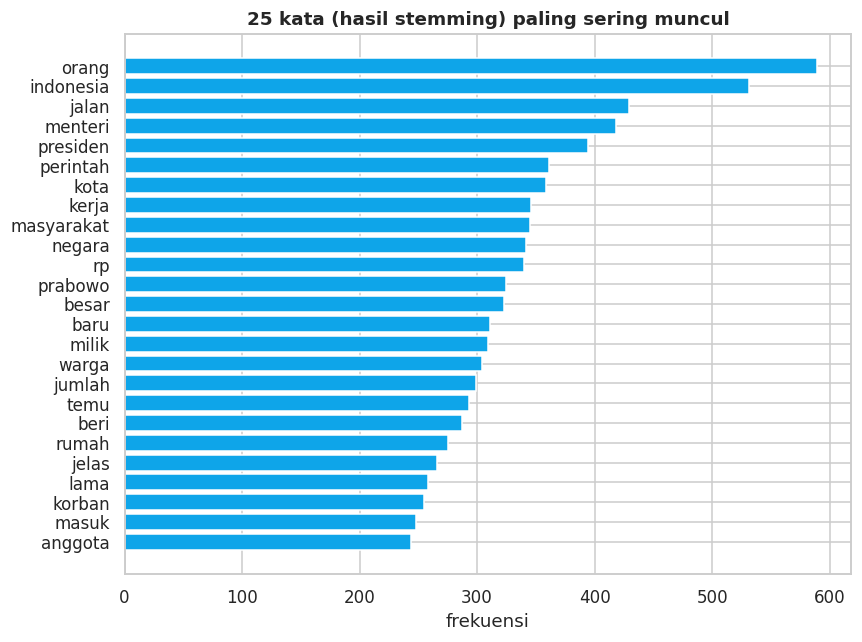

In [19]:
freq = Counter(w for t in df["tok_stem"] for w in t)
top = freq.most_common(25)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color="#0ea5e9")
ax.set(title="25 kata (hasil stemming) paling sering muncul", xlabel="frekuensi")
plt.tight_layout(); plt.show()

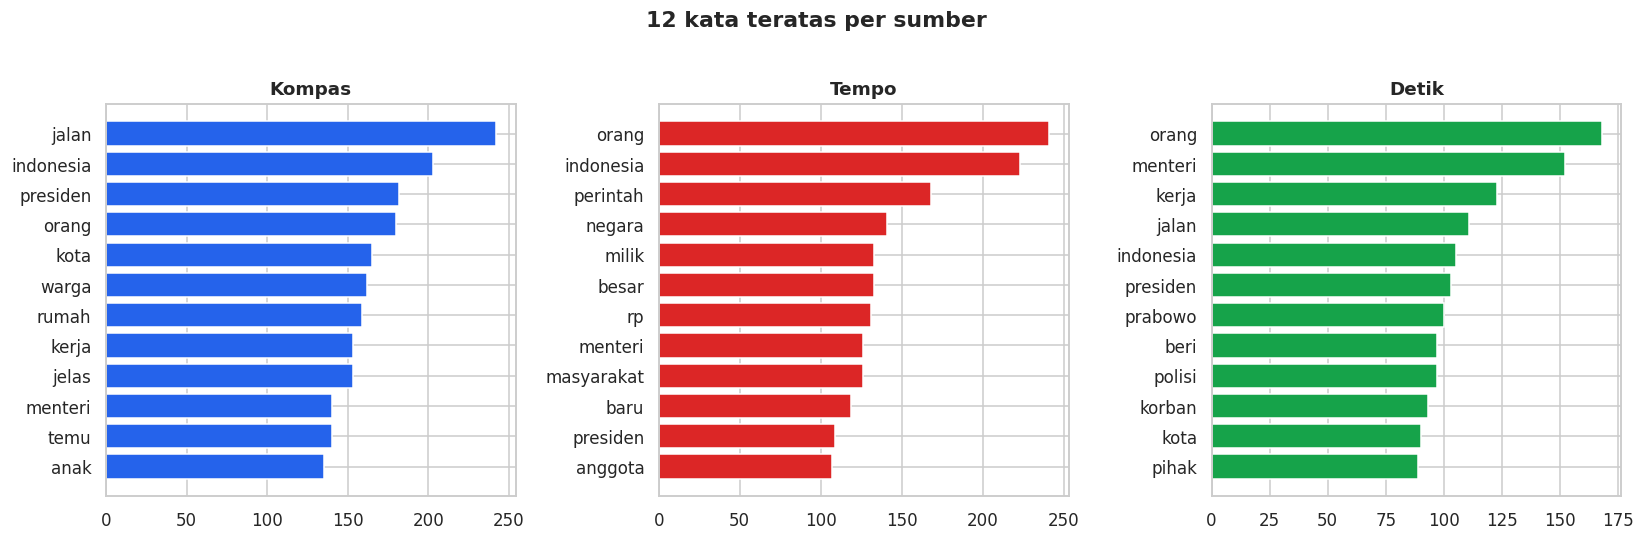

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, s in zip(axes, SOURCES):
    c = Counter(w for t in df.loc[df["source"] == s, "tok_stem"] for w in t).most_common(12)
    ax.barh([w for w, _ in c][::-1], [n for _, n in c][::-1], color=COLORS[s])
    ax.set_title(s.capitalize())
plt.suptitle("12 kata teratas per sumber", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

## 12. Document Frequency dan Kandidat Stopword Domain

Term yang muncul di >= 15% dokumen (kandidat stopword domain):


,df,df_persen
orang,214,42.8
jalan,196,39.2
indonesia,193,38.6
jumlah,177,35.4
masuk,172,34.4
lama,171,34.2
perintah,170,34.0
jelas,170,34.0
milik,165,33.0
baru,164,32.8


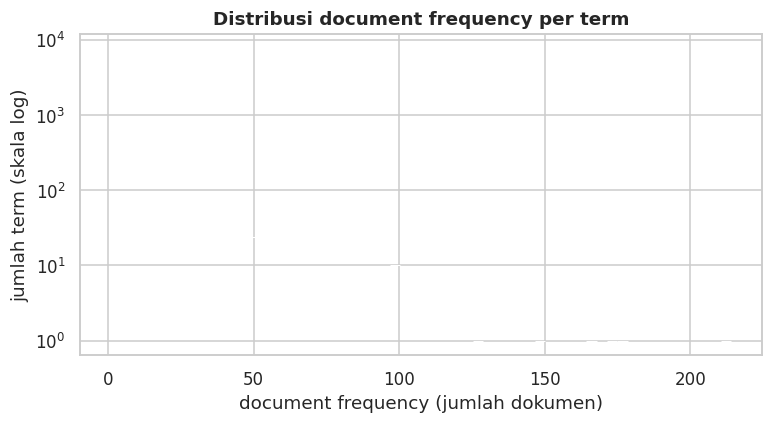

In [21]:
N = len(df)
doc_freq = Counter()
for t in df["tok_stem"]:
    doc_freq.update(set(t))

df_table = pd.DataFrame({"df": pd.Series(doc_freq)})
df_table["df_persen"] = (df_table["df"] / N * 100).round(1)
df_table = df_table.sort_values("df", ascending=False)

print("Term yang muncul di >= 15% dokumen (kandidat stopword domain):")
display(df_table[df_table["df_persen"] >= 15].head(25))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(df_table["df"], bins=60, log_scale=(False, True), color="#475569", ax=ax)
ax.set(title="Distribusi document frequency per term", xlabel="document frequency (jumlah dokumen)", ylabel="jumlah term (skala log)")
plt.show()

**Cara membaca:** term dengan *df* tinggi punya IDF rendah sehingga hampir tidak membantu membedakan dokumen. Kata umum hasil stemming seperti *sebut*, *jadi*, dan *laku* (dari *disebut*, *menjadi*, *dilakukan*) bukan stopword bawaan Sastrawi tetapi muncul di mayoritas artikel, jadi sudah ditambahkan ke `EXTRA_STOPWORDS`. Hati-hati dengan kata bermakna topik seperti *indonesia* atau *perintah* (dari *pemerintah*): df-nya tinggi tetapi masih informatif, jadi jangan dibuang. Di sisi lain, sebagian besar term hanya muncul di 1–2 dokumen, dan term jarang inilah yang memberi daya pembeda tinggi pada TF-IDF.

## 13. Hukum Zipf dan Kata Langka

Dalam korpus bahasa alami, frekuensi kata berbanding terbalik dengan peringkatnya (*f ∝ 1/rank*). Pada grafik log-log hasilnya mendekati garis lurus dengan kemiringan sekitar −1.

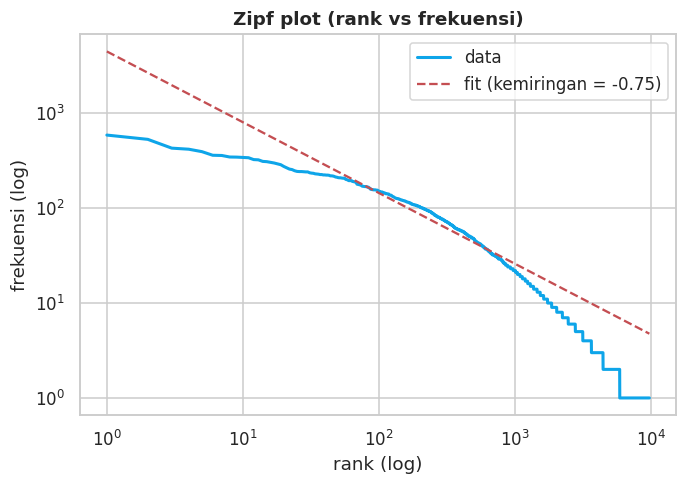

Kosakata unik            : 9744
Hapax legomena (muncul 1x): 3851 (39.5% dari kosakata)
Muncul <= 3x             : 62.6%


In [22]:
frekuensi = np.array(sorted(freq.values(), reverse=True))
rank = np.arange(1, len(frekuensi) + 1)

# Kemiringan pada rentang tengah agar tidak terpengaruh ekor (kata langka)
lo, hi = 10, min(1000, len(frekuensi))
slope, intercept = np.polyfit(np.log10(rank[lo:hi]), np.log10(frekuensi[lo:hi]), 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(rank, frekuensi, color="#0ea5e9", lw=2, label="data")
ax.loglog(rank, 10 ** intercept * rank ** slope, "r--", label=f"fit (kemiringan = {slope:.2f})")
ax.set(title="Zipf plot (rank vs frekuensi)", xlabel="rank (log)", ylabel="frekuensi (log)"); ax.legend()
plt.show()

hapax = sum(1 for c in freq.values() if c == 1)
print(f"Kosakata unik            : {len(freq)}")
print(f"Hapax legomena (muncul 1x): {hapax} ({hapax / len(freq):.1%} dari kosakata)")
print(f"Muncul <= 3x             : {sum(1 for c in freq.values() if c <= 3) / len(freq):.1%}")

Garis yang hampir lurus dengan kemiringan negatif menandakan korpus berperilaku seperti teks bahasa alami. Kemiringan yang lebih landai dari −1 (sekitar −0,8) lazim pada korpus kecil dengan kosakata beragam seperti ini; pada korpus yang jauh lebih besar nilainya biasanya mendekati −1. Proporsi *hapax legomena* yang besar menjelaskan mengapa matriks TF-IDF sangat *sparse* (bagian 15). Kata yang hanya muncul sekali sering berupa nama orang atau tempat, yang justru penting untuk pencarian.

## 14. Bigram Teratas

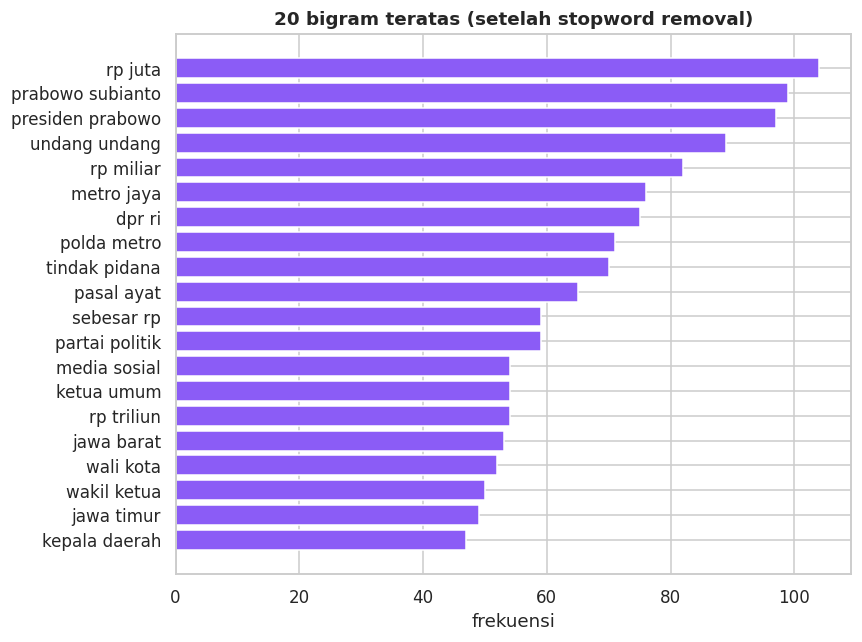

In [23]:
bigram = Counter()
for t in df["tok_nostop"]:
    bigram.update(zip(t, t[1:]))
top_bi = bigram.most_common(20)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([" ".join(b) for b, _ in top_bi][::-1], [c for _, c in top_bi][::-1], color="#8b5cf6")
ax.set(title="20 bigram teratas (setelah stopword removal)", xlabel="frekuensi")
plt.tight_layout(); plt.show()

Bigram menunjukkan entitas dan frasa kunci (nama lembaga, istilah ekonomi, dsb.). Sistem saat ini memakai *bag-of-words* unigram, jadi frasa seperti ini terpecah. Jika hasil pencarian kurang tepat untuk query multi-kata, penambahan bigram ke indeks adalah pengembangan yang masuk akal.

## 15. Kata Khas Tiap Sumber dan Sifat Matriks TF-IDF

Kita bangun matriks TF-IDF (dokumen × term) untuk mengukur *sparsity*, mencari kata yang paling mencirikan tiap portal, dan memeriksa kemiripan antar dokumen.

In [24]:
vec = TfidfVectorizer(analyzer=lambda doc: doc, sublinear_tf=True)   # dokumen sudah berupa daftar token
X = vec.fit_transform(df["tok_stem"])
terms = np.array(vec.get_feature_names_out())

density = X.nnz / (X.shape[0] * X.shape[1])
print(f"Bentuk matriks : {X.shape[0]} dokumen x {X.shape[1]} term")
print(f"Entri non-nol  : {X.nnz}  |  sparsity: {1 - density:.2%}")
print(f"Rata-rata term unik per dokumen: {X.getnnz(axis=1).mean():.0f}")

Bentuk matriks : 500 dokumen x 9744 term
Entri non-nol  : 58774  |  sparsity: 98.79%
Rata-rata term unik per dokumen: 118


In [25]:
khas = {}
for s in SOURCES:
    mask = (df["source"] == s).values
    rata = np.asarray(X[mask].mean(axis=0)).ravel()
    khas[s] = terms[rata.argsort()[::-1][:12]]
display(pd.DataFrame(khas, index=[f"#{i}" for i in range(1, 13)]))

,kompas,tempo,detik
#1,jalan,indonesia,orang
#2,warga,orang,polisi
#3,kota,perintah,pihak
#4,jelas,september,presiden
#5,indonesia,oktober,prabowo
#6,presiden,menteri,menteri
#7,orang,negara,beri
#8,rumah,milik,lihat
#9,temu,besar,lanjut
#10,baik,presiden,kait


Kata dengan bobot TF-IDF rata-rata tertinggi di tiap portal menunjukkan **gaya penulisan dan fokus topik** yang berbeda. Kalau ada istilah yang jelas merupakan sisa format situs, itu tanda noise yang belum dibersihkan.

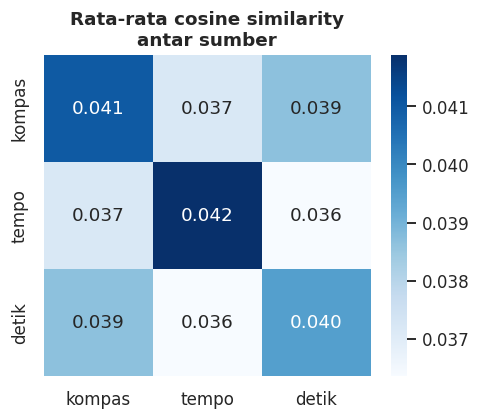

Rata-rata kemiripan antar dokumen: 0.039  |  maksimum: 0.660


In [26]:
# Kemiripan cosine antar dokumen (vektor sudah L2-normal -> cosine = dot product)
S = (X @ X.T).toarray()
np.fill_diagonal(S, np.nan)

src_arr = df["source"].values
rata = pd.DataFrame(index=SOURCES, columns=SOURCES, dtype=float)
for a in SOURCES:
    for b in SOURCES:
        blok = S[np.ix_(src_arr == a, src_arr == b)]
        rata.loc[a, b] = np.nanmean(blok)

fig, ax = plt.subplots(figsize=(4.8, 3.8))
sns.heatmap(rata, annot=True, fmt=".3f", cmap="Blues", ax=ax)
ax.set_title("Rata-rata cosine similarity\nantar sumber")
plt.show()

print(f"Rata-rata kemiripan antar dokumen: {np.nanmean(S):.3f}  |  maksimum: {np.nanmax(S):.3f}")

In [27]:
# Pasangan dokumen yang sangat mirip (kandidat duplikat / berita kembar)
i_idx, j_idx = np.where(np.triu(np.nan_to_num(S, nan=0.0), k=1) >= 0.5)
pasangan = sorted(zip(S[i_idx, j_idx], i_idx, j_idx), reverse=True)
print(f"Pasangan dengan cosine >= 0.5: {len(pasangan)}")
for skor, i, j in pasangan[:5]:
    print(f"\n  skor {skor:.3f}")
    print(f"   [{df['source'][i]}] {df['Judul'][i][:85]}")
    print(f"   [{df['source'][j]}] {df['Judul'][j][:85]}")

Pasangan dengan cosine >= 0.5: 9

  skor 0.660
   [detik] KPK Kirim Surat Panggilan ke Rumdin Paman Birin 2 Kali Tapi Dikembalikan
   [detik] KPK Akan Panggil Gubernur Kalsel Sahbirin Noor Usai Dijadikan Tersangka Suap

  skor 0.653
   [detik] Prabowo Akan Terbitkan Keppres Terkait Abolisi dan Amnesti
   [detik] Sahroni Apresiasi Prabowo Beri Abolisi Tom Lembong: Jaga Stabilitas Nasional

  skor 0.626
   [kompas] KPU Sahkan Hasil Pilkada di Jakarta Utara: Pramono-Rano Kalahkan RK-Suswono
   [kompas] Real Count Pilkada Jakarta: Pramono-Rano Kuasai Jakarta Selatan

  skor 0.618
   [kompas] Jemaat Lansia: Mungkin Kedatangan Paus Berikutnya Saya Sudah Enggak Alami...
   [kompas] Cerita Prodiakon Gereja Santo Ignatius Cuti Kerja 2 Hari demi Misa Kudus Paus Fransis

  skor 0.536
   [tempo] KPK akan Cari Tahu Pemberi Perintah Pembuatan SK Menag saat Periksa Yaqut Cholil Qoum
   [tempo] Belum Tetapkan Tersangka Korupsi Kuota Haji, Ketua KPK: Masalah Waktu Saja


**Interpretasi:** *sparsity* yang tinggi membenarkan penggunaan **inverted index** (hanya term yang ada di dokumen yang disimpan) daripada menghitung dot product pada matriks penuh. Rata-rata kemiripan antar dokumen yang rendah menandakan topik korpus beragam. Pasangan dengan skor tinggi adalah berita yang membahas peristiwa yang sama (sering dari portal berbeda) atau duplikat. Pasangan seperti ini perlu diperhitungkan saat menilai relevansi, karena keduanya akan muncul berdampingan di hasil.

## 16. Cakupan Korpus terhadap Query Uji

Sebelum evaluasi, pastikan query uji punya cukup dokumen yang membahasnya. Query yang tidak ditemukan satu pun term-nya di korpus (*out-of-vocabulary*) tidak akan pernah menghasilkan hasil.

In [28]:
contoh_query = ["PHK pabrik rokok", "gempa bumi Maluku", "banjir Jakarta", "harga beras naik",
                "korupsi", "Prabowo", "timnas sepak bola", "kurs rupiah dolar", "vaksin covid"]

rows = []
for q in contoh_query:
    tokens = preprocess(q)
    dfs = {t: doc_freq.get(t, 0) for t in tokens}
    rows.append({
        "query": q,
        "token (setelah preprocessing)": ", ".join(tokens),
        "df tiap token": ", ".join(f"{t}={n}" for t, n in dfs.items()),
        "OOV": ", ".join(t for t, n in dfs.items() if n == 0) or "-",
    })
display(pd.DataFrame(rows).set_index("query"))

,token (setelah preprocessing),df tiap token,OOV
query,,,
PHK pabrik rokok,"phk, pabrik, rokok","phk=4, pabrik=8, rokok=6",-
gempa bumi Maluku,"gempa, bumi, malu","gempa=6, bumi=14, malu=10",-
banjir Jakarta,banjir,banjir=17,-
harga beras naik,"harga, beras, naik","harga=43, beras=0, naik=45",beras
korupsi,korupsi,korupsi=36,-
Prabowo,prabowo,prabowo=85,-
timnas sepak bola,"timnas, sepak, bola","timnas=4, sepak=3, bola=7",-
kurs rupiah dolar,"kurs, rupiah, dolar","kurs=1, rupiah=7, dolar=1",-
vaksin covid,"vaksin, covid","vaksin=1, covid=4",-


Gunakan tabel ini untuk memilih query pengujian yang punya dokumen relevan (df cukup, misalnya ≥ 3). Query dengan token OOV adalah contoh bagus untuk menguji bagaimana sistem menangani "tidak ada hasil".

## 17. Ringkasan Temuan dan Rekomendasi

In [29]:
sisa_noise = int(noise_df["sisa setelah clean_text"].sum())
ringkasan = [
    f"Dataset terdiri dari {len(df)} artikel dari {df['source'].nunique()} sumber "
    f"(terbanyak: {src_count.idxmax()} {src_pct.max():.0f}%).",
    f"Kolom Judul dan Content tidak ada yang kosong; nilai kosong hanya pada tag "
    f"({missing.loc['tag5', 'persen']:.0f}% pada tag5).",
    f"Duplikat: {int(dup['Link duplikat'])} link dan {int(dup['Judul duplikat'])} judul.",
    f"Rentang waktu {df['waktu_dt'].min().date()} s.d. {df['waktu_dt'].max().date()}; "
    f"{df['waktu_dt'].isna().sum()} tanggal gagal diparse.",
    f"Median panjang artikel {df['n_kata'].median():.0f} kata; {len(outlier)} outlier menurut IQR.",
    f"Preprocessing menyusutkan kosakata dari {stat['kosakata unik'].iloc[0]} menjadi {stat['kosakata unik'].iloc[-1]} term "
    f"({1 - stat['kosakata unik'].iloc[-1] / stat['kosakata unik'].iloc[0]:.0%}).",
    f"Kemiringan Zipf {slope:.2f}; {hapax / len(freq):.0%} kosakata hanya muncul sekali.",
    f"Matriks TF-IDF {X.shape[0]} x {X.shape[1]} dengan sparsity {1 - density:.2%}.",
    f"Sisa noise setelah clean_text: {sisa_noise} kemunculan pola yang dipantau.",
]
for i, r in enumerate(ringkasan, 1):
    print(f"{i}. {r}")

1. Dataset terdiri dari 500 artikel dari 3 sumber (terbanyak: kompas 47%).
2. Kolom Judul dan Content tidak ada yang kosong; nilai kosong hanya pada tag (58% pada tag5).
3. Duplikat: 0 link dan 0 judul.
4. Rentang waktu 2024-07-31 s.d. 2025-10-23; 0 tanggal gagal diparse.
5. Median panjang artikel 295 kata; 28 outlier menurut IQR.
6. Preprocessing menyusutkan kosakata dari 14090 menjadi 9744 term (31%).
7. Kemiringan Zipf -0.75; 40% kosakata hanya muncul sekali.
8. Matriks TF-IDF 500 x 9744 dengan sparsity 98.79%.
9. Sisa noise setelah clean_text: 0 kemunculan pola yang dipantau.


### Rekomendasi tahap berikutnya

1. **Pantau noise baru** (bagian 9) setiap kali dataset diperbesar atau portal ditambah, dan perbarui `EXTRA_STOPWORDS` berdasarkan daftar *document frequency* tinggi (bagian 12).
2. **Periksa kredit redaksi yang tersisa** (misalnya "Editor: ... Videographer" di akhir artikel Tempo). Jumlahnya kecil, tetapi bisa ditambahkan ke `_NOISE_PATTERNS` jika mengganggu.
3. **Gunakan `waktu_dt`** yang sudah distandarkan (bagian 5) bila ingin fitur filter atau pengurutan berdasarkan tanggal. Simpan sebagai kolom baru, jangan menimpa kolom `Waktu` asli.
4. **Evaluasi** dengan query dari bagian 16, dan jadikan tag sebagai petunjuk relevansi awal. Hitung Precision@K, Recall, dan MAP.
5. **Eksperimen lanjutan:** tambah bigram ke indeks, bandingkan dengan `TfidfVectorizer` scikit-learn, atau coba BM25 sebagai pembanding.
6. **Skala data:** dataset asli berisi 80 ribu artikel. Bila nanti diperbesar, stemming harus dijalankan paralel dan indeks disimpan ke disk (sudah didukung `build_index.py`).